In [3]:
%pylab inline
import os
import gc
import healpy as hp
import numpy as np
import astropy.io.fits as pyfits
import astropy.table as astTable
import catutil as utilities
inDir='./wrkDir/database/s19-COSMOS/origin/'
outDir='./wrkDir/database/s19-COSMOS/origin/%s-nside512/'
hpfname='./wrkDir/database/s19a_fdfc_hp_contarea_izy-gt-5_trimmed_fd001.fits'
hpSet=np.array([1743733, 1743734, 1743735, 1743737, 1743739, 1743740, 1743741,
       1743742, 1743743, 1743825, 1743828, 1743829, 1743830, 1743831,
       1743837, 1744390, 1744391, 1744393, 1744394, 1744395, 1744396,
       1744397, 1744398, 1744399, 1744402, 1744403, 1744406, 1744408,
       1744409, 1744410, 1744411, 1744412, 1744413, 1744414, 1744415,
       1744416, 1744417, 1744418, 1744419, 1744420, 1744421, 1744422,
       1744423, 1744424, 1744425, 1744426, 1744427, 1744428, 1744429,
       1744430, 1744431, 1744432, 1744433, 1744434, 1744435, 1744436,
       1744437, 1744438, 1744439, 1744440, 1744441, 1744442, 1744443,
       1744444, 1744445, 1744446, 1744447, 1744456, 1744458, 1744459,
       1744480, 1744481, 1744482, 1744483, 1744484, 1744486, 1744487,
       1744488, 1744489, 1744490, 1744491, 1744492, 1744493, 1744494,
       1744495, 1744506, 1744512, 1744513, 1744514, 1744515, 1744516,
       1744517, 1744518, 1744519, 1744520, 1744521, 1744522, 1744523,
       1744524, 1744525, 1744526, 1744527, 1744528, 1744529, 1744530,
       1744531, 1744532, 1744533, 1744534, 1744535, 1744536, 1744537,
       1744538, 1744539, 1744540, 1744541, 1744542, 1744543, 1744545,
       1744548, 1744549, 1744550, 1744551, 1744557, 1744560, 1744561,
       1744562, 1744563, 1744564, 1744565, 1744566, 1744567, 1744568,
       1744569, 1744570, 1744571, 1744572, 1744573, 1744574, 1744575,
       1744576, 1744577, 1744578, 1744579, 1744580, 1744581, 1744582,
       1744583, 1744584, 1744585, 1744586, 1744587, 1744588, 1744589,
       1744590, 1744591, 1744592, 1744594, 1744600, 1744602, 1744608,
       1744609, 1744610, 1744611, 1744612, 1744613, 1744614, 1744616,
       1744617, 1744618, 1750033, 1750036, 1750037])

Populating the interactive namespace from numpy and matplotlib


In [29]:
nside   =   512
# Split into healpix with nside=256
snList=['BEST','MEDIAN','WORST']
for ssname in snList[2:]:
    fname=os.path.join(inDir,'COSMOS_WIDE_DEPTH_%s.fits' %ssname)
    data=pyfits.getdata(fname)
    ra,dec  =   utilities.get_radec(data)
    # Get flag
    mfactor =   np.pi/180.
    phi     =   ra*mfactor
    theta   =   np.pi/2. - dec*mfactor
    hpinds  =   hp.ang2pix(nside, theta, phi, nest = True)
    hpSet   =   np.unique(hpinds)
    for pixId in hpSet:
        vec=hp.boundaries(nside=nside,pix=pixId,nest=True).T
        raBs,decBs=hp.vec2ang(vec,lonlat=True)
        raMax=raBs.max()+0.02
        decMax=decBs.max()+0.02
        raMin=raBs.min()-0.02
        decMin=decBs.min()-0.02
        raC=(raMin+raMax)/2.
        decC=(decMin+decMax)/2.
        mask2=(ra>raMin)&(ra<raMax)&(dec>decMin)&(dec<decMax)
        mask=(hpinds==pixId)
        if np.sum(mask)>100:
            outfname=os.path.join(outDir %ssname,'%d.fits' %pixId)
            pyfits.writeto(outfname,data[mask2],overwrite=True)
    del data,mask,mask2
    gc.collect()

In [25]:
import numpy as np
import healpy as hp
import fitsio
nside=128
npix=hp.nside2npix(nside)
pixAll=np.arange(npix)
vec=hp.boundaries(nside=nside,pix=pixAll,nest=True)
vec=np.swapaxes(vec,1,2)
raBs,decBs=hp.vec2ang(vec,lonlat=True)
raBs[raBs<1e-6]=360.

raBs=raBs.reshape((npix,4))
decBs=decBs.reshape((npix,4))
# neglect data from poles
mask=(decBs[:,0]<85)&(decBs[:,2]>-85)
raBs=raBs[mask]
decBs=decBs[mask]
pixAll=pixAll[mask]
# the healpix cross ra=0.
maskMax=np.abs(raBs[:,3]-np.max(raBs,axis=1))>1e-3
raBs[:,3][maskMax]=raBs[:,3][maskMax]+360.
# maximum and minimum
raMax=raBs[:,3]+0.02;raMin=raBs[:,1]-0.02
decMax=decBs[:,0]+0.02;decMin=decBs[:,2]-0.02
raC=(raMin+raMax)/2.
decC=(decMin+decMax)/2.
dra=raMax-raMin;ddec=decMax-decMin

types=[('pix','i4'),('raMin','>f8'),('raMax','>f8'),('decMin','>f8'),('decMax','>f8'),('dra','>f8'),('ddec','>f8')]
data=np.stack([pixAll,raMin,raMax,decMin,decMax,dra,ddec]).T
data=[tuple(ii) for ii in data]
out=np.array(data,dtype=types)
fitsio.write('/work/xiangchong.li/work/skyMap/healpix-nside%d-nest.fits' %nside,out)

0.2157373249795569 0.1590758303766786


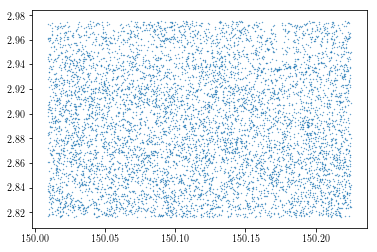

In [14]:
pixId=hpSet[-10]
outfname=os.path.join(outDir %ssname,'%d.fits' %pixId)
a=pyfits.getdata(outfname)
ra,dec=utilities.get_radec(a)
plt.close()
plt.scatter(ra,dec,s=0.1)
print(ra.max()-ra.min(),dec.max()-dec.min())

In [11]:
print((raMax-raMin)*3600/0.168)
print(decMax)

4623.883928571867
3.0055060057465295


In [1]:
import galsim
import fitsio
import smatch

In [ ]:
# training data
directory   =   '/work/xiangchong.li/work/COSMOS/galsim_train/COSMOS_25.2_training_sample/'
ooDir=os.path.join(directory,'healpix-nside512')
if not os.path.isdir(ooDir):
    os.mkdir(ooDir)
catName     =   'real_galaxy_catalog_25.2.fits'
cosmos_cat  =   galsim.COSMOSCatalog(catName,dir=directory)

# used index
index_use   =   cosmos_cat.orig_index
# used catalog
paracat=cosmos_cat.param_cat[index_use]
# parametric catalog
param_cat   =   cosmos_cat.param_cat[index_use]
oricat      =   fitsio.read(cosmos_cat.real_cat.getFileName())[index_use]
ngAll       =   len(index_use)
ra      = oricat['RA']
dec     = oricat['DEC']
# Get flag
mfactor =   np.pi/180.
phi     =   ra*mfactor
theta   =   np.pi/2. - dec*mfactor
hpinds  =   hp.ang2pix(nside, theta, phi, nest = True)
hpSet   =   np.unique(hpinds)
indAll  =   np.arange(len(hpinds),dtype=np.int)

In [6]:
paracat.dtype.names

('IDENT',
 'mag_auto',
 'flux_radius',
 'zphot',
 'sersicfit',
 'bulgefit',
 'fit_status',
 'fit_mad_s',
 'fit_mad_b',
 'fit_dvc_btt',
 'use_bulgefit',
 'viable_sersic',
 'hlr',
 'flux')

In [28]:
nall=0.
for pixId in hpSet:
    ofname  =   os.path.join(ooDir,'%d-25.2_ind.fits' %pixId)
    vec=hp.boundaries(nside=nside,pix=pixId,nest=True).T
    raBs,decBs=hp.vec2ang(vec,lonlat=True)
    raMax=raBs.max()+0.02
    decMax=decBs.max()+0.02
    raMin=raBs.min()-0.02
    decMin=decBs.min()-0.02
    raC=(raMin+raMax)/2.
    decC=(decMin+decMax)/2.
    mask2=(ra>raMin)&(ra<raMax)&(dec>decMin)&(dec<decMax)
    mask=(hpinds==pixId)
    if np.sum(mask)>100:
        pyfits.writeto(ofname,indAll[mask2],overwrite=True)
    nall+=np.sum(mask2)
    del mask,mask2
print(nall)

253160.0


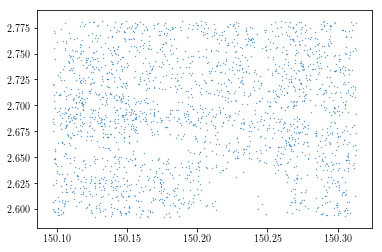

In [36]:
pixId=hpSet[-23]
ofname  =   os.path.join(ooDir,'%d-25.2_ind.fits' %pixId)
ind=fitsio.read(ofname)
data=oricat[ind]
plt.close()
plt.scatter(data['RA'],data['DEC'],s=0.1)

In [9]:
from pixel3D import cartesianGrid3D
from configparser import ConfigParser
parser  =   ConfigParser()
configName='./wrkDir/s19/s19-cosmos/config-nl1.ini'
parser.read(configName)
gridInfo=   cartesianGrid3D(parser)

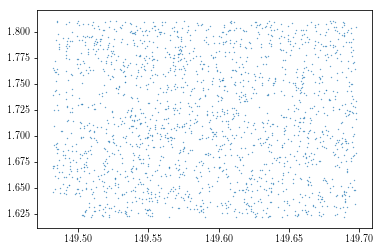

In [14]:
nside=512
out=pyfits.getdata('/work/xiangchong.li/work/skyMap/healpix-nside%d-nest.fits' %nside)
for pixId in hpSet[10:11]:
    dd=out[out['pix']==pixId]
    nx=int(dd['dra']/gridInfo.delta)
    ny=int(dd['ddec']/gridInfo.delta)
    gridInfo.setupNaivePlane(nx,ny,dd['raMin'],dd['decMin'])
    ofname  =   os.path.join(ooDir,'%d-25.2_ind.fits' %pixId)
    ind=pyfits.getdata(ofname)
    x,y=gridInfo.project_tan(oricat[ind]['RA'],oricat[ind]['DEC'],pix=True)
    xI=np.int_(x)
    yI=np.int_(y)
    plt.scatter(oricat[ind]['RA'],oricat[ind]['DEC'],s=0.1)
    break

In [15]:
nx

4623

In [16]:
ny

4055

In [166]:
bigfft      =   galsim.GSParams(maximum_fft_size=10240)
scale=0.168
flux_scaling=   2.587
variance    =   0.0035
ud          =   galsim.UniformDeviate(int(pixId))
np.random.seed(1)

psfInt=galsim.Moffat(beta=3.5,fwhm=0.615,trunc=0.615*4.)
psfInt=psfInt.shear(e1=0.,e2=0.02)
psfImg   =   psfInt.drawImage(nx=45,ny=45,scale=scale)

gal_image  =   galsim.ImageF(nx,ny,scale=scale)
gal_image.setOrigin(0,0)
for i,iid  in enumerate(ind):
    ss      =   oricat[iid]
    if xI[i]-32>0 and xI[i]+32<nx and yI[i]-32>0 and yI[i]+32<ny:
        gal0    =   cosmos_cat.makeGalaxy(gal_type='parametric',index=iid,gsparams=bigfft)
        gal0    *=  flux_scaling
        gal1    =   gal0.shear(g1=-0.02,g2=0.)
        final1  =   galsim.Convolve([psfInt,gal1],gsparams=bigfft)

        b       =   galsim.BoundsI(xI[i]-32,xI[i]+32,yI[i]-32,yI[i]+32)
        sub_img =   gal_image[b]
        final1.drawImage(sub_img,add_to_image=True)
        del gal0,gal1,final1,b,sub_img
        gc.collect()

In [167]:
gal_image.write('aaa.fits')